# 06 — Cotação de grupo novo

A ferramenta do dia a dia: recebe o censo de vidas de um grupo e devolve a taxa pura e a comercial (mensal, por mil de
capital), a decomposição do custo e os alertas de subscrição. **Não exige R**: usa só a tabela de fatores da taxa
manual (03b) e a tábua.

$$
\text{prêmio puro} = \sum_{\text{vidas}} q_x \cdot f_{\text{manual}} \cdot \min(C, P) \;+\; \underbrace{\sum_{\text{vidas}} q_x \cdot f_{\text{manual}} \cdot \max(C - P, 0)}_{\text{encargo de pooling}},
\qquad
\text{taxa comercial} = \text{taxa pura}\cdot\frac{1 + \text{margem}}{1 - \text{carregamentos}}
$$

em que $f_{\text{manual}}$ é o fator da taxa manual (A/E base × seção × divisão × capital) e $P$ o nível de pooling do
grupo. Carregamentos e limites dos alertas estão em `config/cotador.yaml` e são **política da seguradora** (valores
ilustrativos).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M
from vgpricing.cotador import cotar
from vgpricing.io import ler_excel

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cc, cr, mapas = (carregar_config(n, RAIZ) for n in ("base", "cotador", "renovacao", "colunas"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")
print("Taxa manual:", tabela["meta"]["modelo_escolhido"], "| experiência até", tabela["meta"]["corte_experiencia"])

Taxa manual: ridge com priori SOA | experiência até 2024-12-31


## 1. Entrada

Na operação, o censo vem do template Excel (`templates/entrada_vida_grupo.xlsx`, abas `estipulantes` e `vidas`):

```python
dados, problemas = ler_excel("cotacao_cliente.xlsx", mapas)
censo, estip = dados["vidas"], dados["estipulantes"].iloc[0]
```

Aqui, para demonstrar, o censo é o de um grupo da carteira sintética, cotado como se fosse novo.

In [2]:
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
vidas, estips = pd.read_parquet(limpo / "vidas.parquet"), pd.read_parquet(limpo / "estipulantes.parquet")
ativos = vidas[vidas["data_fim"].isna()]
porte = ativos["id_estipulante"].value_counts()
exemplos = {"pequeno": porte.index[int(len(porte) * 0.9)], "mediano": porte.index[len(porte) // 2], "grande": porte.index[5]}
INICIO = pd.Timestamp(cfg["data_referencia"]) + pd.Timedelta(days=1)
linhas, alertas = [], {}
for nome, g in exemplos.items():
    censo = ativos[ativos["id_estipulante"] == g][["data_nascimento", "sexo", "capital"]]
    e = estips.set_index("id_estipulante").loc[g]
    r = cotar(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, INICIO, cc, cr)
    alertas[nome] = r.pop("alertas")
    linhas.append({"grupo": f"{nome} ({g})", "atividade": f"{e['cnae_secao']}:{e['cnae_divisao']}", **r})
cot = pd.DataFrame(linhas).set_index("grupo")
cot[["atividade", "vidas", "capital_total", "nivel_pooling", "encargo_pooling", "premio_puro_anual",
     "taxa_pura_mensal_mil", "taxa_comercial_mensal_mil"]]

,atividade,vidas,capital_total,nivel_pooling,encargo_pooling,premio_puro_anual,taxa_pura_mensal_mil,taxa_comercial_mensal_mil
grupo,,,,,,,,
pequeno (EST0048),K:64,62,"3,420,000.0000","165,483.8710",0.0000,"5,730.4000",0.1396,0.2243
mediano (EST0013),G:46,466,"89,493,700.0000","576,139.6996","1,894.1127","114,917.4888",0.1070,0.1719
grande (EST0092),G:45,4856,"97,120,000.0000","100,000.0000",0.0000,"166,301.6911",0.1427,0.2293


## 2. Alertas de subscrição

In [3]:
pd.concat(alertas, names=["grupo"]).reset_index(level=0).query("disparou")[["grupo", "alerta", "detalhe"]]

,grupo,alerta,detalhe
2,pequeno,concentração: 10 maiores capitais,10 maiores = 38.6% do total


Os alertas não mudam a taxa: indicam o que a subscrição precisa olhar antes de emitir (resseguro facultativo para
capitais acima da retenção, concentração que torna o resultado do grupo dependente de poucas vidas, idades fora da
aceitação, grupo pequeno demais para a taxa média).

## 3. De onde vem a taxa (decomposição para o corretor ou o subscritor)

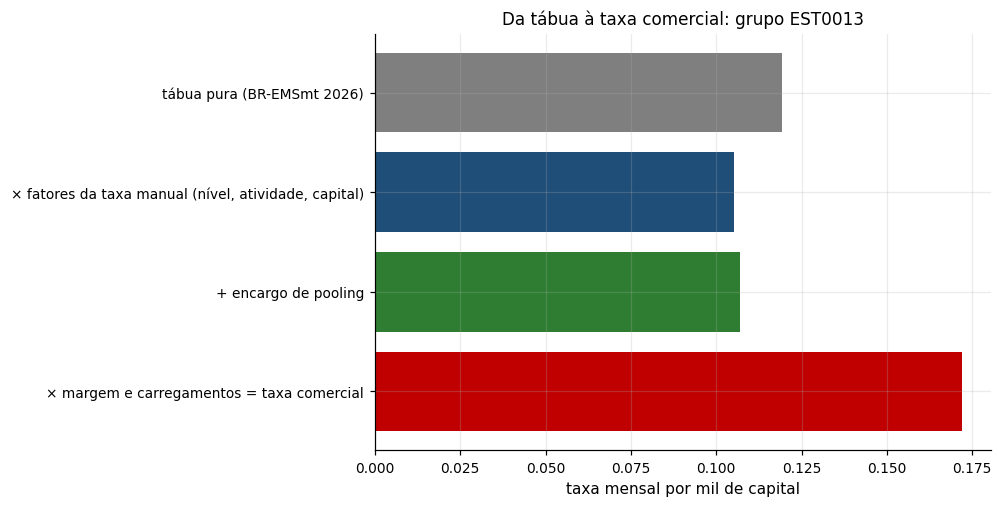

,taxa mensal (‰)
tábua pura (BR-EMSmt 2026),0.1193
"× fatores da taxa manual (nível, atividade, capital)",0.1052
+ encargo de pooling,0.1070
× margem e carregamentos = taxa comercial,0.1719


In [4]:
g = exemplos["mediano"]
censo = ativos[ativos["id_estipulante"] == g][["data_nascimento", "sexo", "capital"]]
e = estips.set_index("id_estipulante").loc[g]
r = cotar(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, INICIO, cc, cr)
tabua_pura = M.taxa_pura_manual(censo, e["cnae_secao"], e["cnae_divisao"],
                                {**tabela, "ae_base": 1.0, "secao": {}, "secao_nao_vista": 1.0,
                                 "capital": {**tabela["capital"], "elasticidade": 0.0}}, tabua, INICIO)
passos = pd.Series({"tábua pura (BR-EMSmt 2026)": tabua_pura["taxa_pura_mensal_mil"],
                    "× fatores da taxa manual (nível, atividade, capital)": r["taxa_pura_mensal_mil"] - r["encargo_pooling"] / r["capital_total"] * 1000 / 12,
                    "+ encargo de pooling": r["taxa_pura_mensal_mil"],
                    "× margem e carregamentos = taxa comercial": r["taxa_comercial_mensal_mil"]})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(range(len(passos)), passos.values, color=["#7f7f7f", "#1f4e79", "#2e7d32", "#c00000"])
ax.set_yticks(range(len(passos)), passos.index); ax.invert_yaxis()
ax.set_xlabel("taxa mensal por mil de capital"); ax.set_title(f"Da tábua à taxa comercial: grupo {g}")
plt.show()
passos.to_frame("taxa mensal (‰)")